# Eksplorujemy modele `text-to-embeddings`: `openai/text-embedding-3-small` oraz `openai/text-embedding-3-large`

## Czym są text embeddings?

* Text embeddings to reprezentacja tekstu w przestrzeni wektorowej.
* Pozwalają na reprezentację tekstu w taki sposób, aby zachować jego semantykę (czyli znaczenie).
* Mówiąc po ludzku potrafimy zamienić tekst na wektor (ciąg liczb), który zachowuje znaczenie tekstu.
* Możemy wówczas wykonywać operacje na tych wektorach, np. obliczać podobieństwo między tekstami!

## Czym są modele `text-emdedding-3-small` oraz `text-embedding-3-large`?

* `text-emdedding-3-small` oraz `text-emdedding-3-large` to modele `text-to-embedding` stworzone przez OpenAI.
* Potrafią zamienić tekst na wektor.
* Działa w wielu językach.
* [Dokumentacja](https://platform.openai.com/docs/guides/embeddings)  
* Wejście: tekst
* Wyjście: wektor

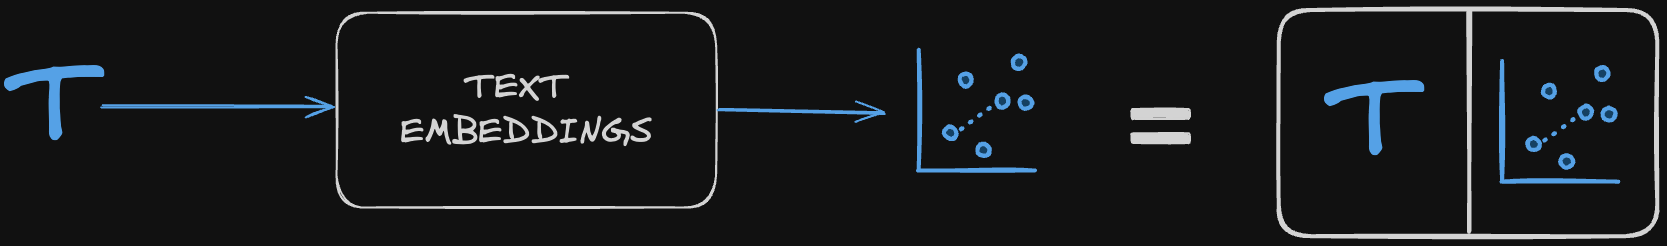

## Koszty

* Modele do generowanie embeddingów są płatne i względnie tanie.
* Koszt zależy od ilości tzw. tokenów (znaków) w tekście.
* Token można sobie wyobrazić jako pojedynczą sylabę lub krótkie słowo.
* Koszt za milion tokenów to `$0.02` (czyli około `0.08 PLN`) dla `text-embedding-3-small` oraz `$0.13` (czyli około `0.52 PLN`) dla `text-embedding-3-large`.

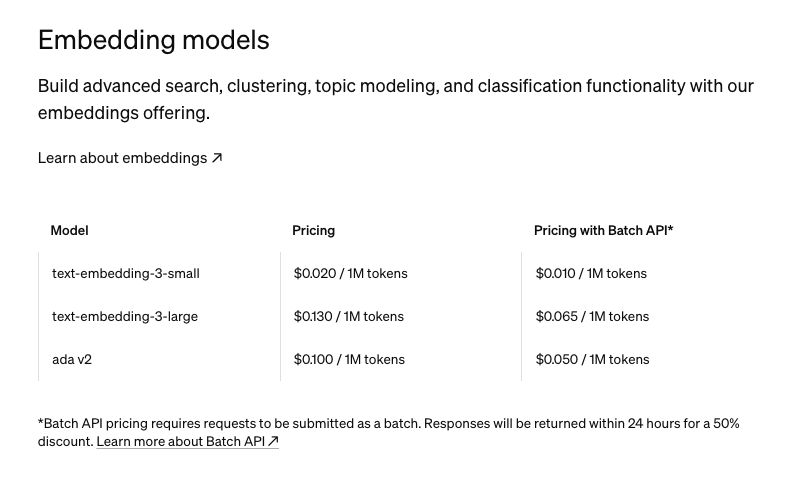

## Instalujemy wymagane biblioteki (conda wymagana)

- otwórz terminal
- uruchom `conda activate od_zera_do_ai`
- uruchom `conda install -y openai==1.97.1 tiktoken python-dotenv`

In [ ]:
from dotenv import dotenv_values
from openai import OpenAI
import tiktoken

In [ ]:
env = dotenv_values(".env")

openai_client = OpenAI(api_key=env["OPENAI_API_KEY"])

## Czym są tokeny?

Tokeny to specjalne znaki, które są rozpoznawane przez model. Tokenem może być sylaba, słowo, znak interpunkcyjny, itp.

Do generowania tokenów możemy użyć biblioteki `tiktoken`.

In [ ]:
# enc daje dostęp do `encode`, która potrafi konwertować tekst na tokeny
enc = tiktoken.encoding_for_model("gpt-4o")

In [ ]:
text = "Witaj świecie jak się masz?"
tokens = enc.encode(text)

print(f"Tekst: '{text}' o długości {len(text)} ma tokenów: {len(tokens)}")

In [ ]:
tokens

## Jak tworzyć embeddings-y?

In [ ]:
result = openai_client.embeddings.create(
    input=[
        "Dawno temu w trawie",
        "Gdzieś na końcu świata",
        "W krainie czarów",
    ],
    model="text-embedding-3-large",
)

In [ ]:
len(result.data[0].embedding)

In [ ]:
result.data[0].embedding[:10]

## Zamykamy model w funkcji

In [ ]:
def calculate_embedding(text):
    result = openai_client.embeddings.create(
        input=[text],
        model="text-embedding-3-large",
    )

    return result.data[0].embedding

In [ ]:
embedding_vector = calculate_embedding("Dawno temu w trawie")
embedding_vector[:10]

## Pomysły `gpt-4o` na użycie modelu

### 1. Semantyczne Przeszukiwanie Notatek
Użytkownicy mogą przesyłać swoje notatki (tekstowe) do systemu, który przekształci je w embeddings. Dzięki temu mogą semantycznie przeszukiwać swoje notatki, znajdując informacje na podstawie podobieństwa kontekstowego, a nie tylko słów kluczowych.

### 2. Rekomendacje Artykułów
System może analizować artykuły lub posty na blogach i tworzyć dla nich embeddings. Następnie, na podstawie tekstu, który użytkownik przeczytał lub napisał, można generować rekomendacje innych treści, które są semantycznie podobne.

### 3. Inteligentne Wyszukiwanie Dokumentów w Firmie
W organizacji model AI może przekształcać wszystkie dokumenty (raporty, prezentacje, e-maile) w embeddings. Użytkownicy mogą zadawać pytania lub wprowadzać opisy, a system wyszuka najbardziej odpowiednie dokumenty, uwzględniając kontekst i treść, a nie tylko słowa kluczowe.

### 4. Analiza Nastroju Klienta w Obsłudze Klienta
Model AI może przekształcać treści e-maili i wiadomości od klientów w embeddings, a następnie analizować je pod kątem nastroju lub intencji. Dzięki temu można lepiej dostosować odpowiedzi lub eskalować problemy wymagające uwagi.

### 5. Generowanie Embeddings dla Opisów Obrazów i Wideo
System może generować opisy do zdjęć lub filmów, a następnie przekształcać te opisy w embeddings. Umożliwia to wyszukiwanie i rekomendowanie obrazów lub filmów na podstawie podobieństwa semantycznego do wprowadzonego tekstu.

### 6. Klasyfikacja Tematyczna Książek lub Artykułów
Model AI może przekształcać teksty książek, artykułów czy rozdziałów w embeddings, a następnie klasyfikować je tematycznie. Dzięki temu można łatwo organizować duże zbiory literatury lub archiwa w sposób kontekstualny.

### 7. Rekomendacje Produktów na Podstawie Opinii Klientów
Przekształcenie recenzji produktów w embeddings umożliwia analizę podobieństw między opiniami klientów. Na tej podstawie można rekomendować produkty, które są najbardziej podobne do tych, które użytkownik lubił w przeszłości.

### 8. Personalizowane Treści Edukacyjne
System może przekształcać materiały edukacyjne, takie jak podręczniki, kursy online i artykuły, w embeddings. Następnie na podstawie testów lub pytań od ucznia, można rekomendować materiały, które są najlepiej dopasowane do jego potrzeb i poziomu wiedzy.

### 9. Analiza Trendów na Podstawie Tekstów w Mediach Społecznościowych
Model AI może przekształcać posty w mediach społecznościowych w embeddings i analizować je pod kątem pojawiających się trendów lub opinii publicznej. Dzięki temu firmy mogą reagować na zmieniające się nastroje konsumentów.

### 10. Zaawansowane Wyszukiwanie w Poczcie E-mail
Przekształcenie treści e-maili w embeddings umożliwia zaawansowane wyszukiwanie w poczcie. Użytkownicy mogą wprowadzać pytania lub opisy, a system znajdzie najbardziej odpowiednie e-maile, biorąc pod uwagę ich treść i kontekst.